# ARTI403 – Image Processing
## Lab 6: Frequency Domain

**Student Name:** Danyal Salman Alhashem  
**Student ID:** 2240002713

**Outcome:** Write a program that implements fundamental image processing algorithms.

This notebook contains:
1. **Procedure Task #1** – Laplacian filtering in the frequency domain.
2. **Assessment Task #1** – Sobel filtering in the frequency domain on the same Cameraman image.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io
from skimage.transform import resize
from skimage.util import img_as_ubyte
from numpy.fft import fft2, ifft2, fftshift, ifftshift, fftfreq
import os

os.makedirs('images', exist_ok=True)

## Procedure Task #1: Laplacian Filtering in the Frequency Domain

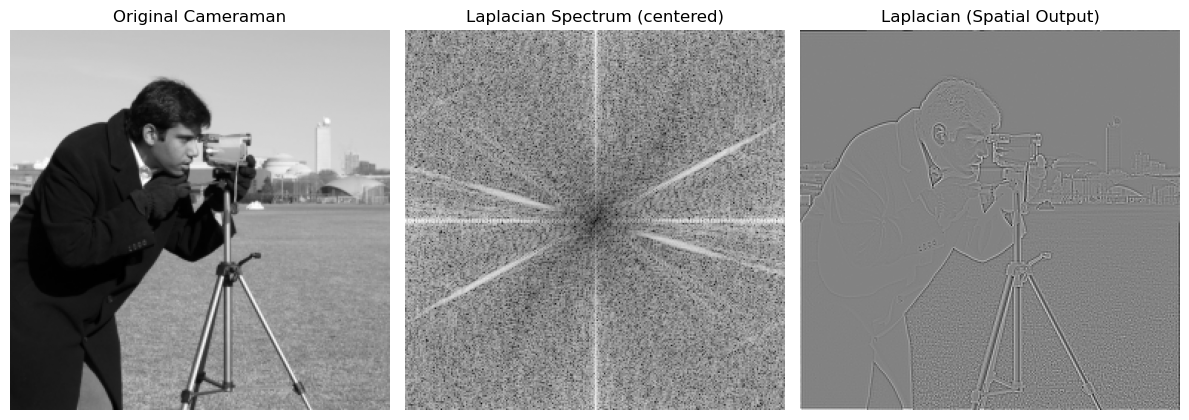

In [2]:
# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))   # Resize for faster FFT (values in [0, 1])
io.imsave('images/cameraman_256.png', img_as_ubyte(image))

# Get image size
M, N = image.shape

# Generate frequency grid
u = fftfreq(M).reshape(-1, 1)
v = fftfreq(N).reshape(1, -1)

# Laplacian filter in frequency domain: H(u,v) = -4*pi^2*(u^2 + v^2)
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# 2D FFT, multiply, inverse FFT
F = fft2(image)
F_lap = F * laplacian_filter
laplacian_image = ifft2(F_lap).real

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1); plt.imshow(image, cmap='gray'); plt.title('Original Cameraman'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(np.log(1 + np.abs(fftshift(F_lap))), cmap='gray'); plt.title('Laplacian Spectrum (centered)'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(laplacian_image, cmap='gray'); plt.title('Laplacian (Spatial Output)'); plt.axis('off')
plt.tight_layout()
plt.savefig('images/task1_laplacian.png', dpi=120)
plt.show()

## Assessment Task #1: Sobel Filters in the Frequency Domain

**Idea (Convolution Theorem):** convolution in the spatial domain equals multiplication in the frequency domain:

$$ f(x,y) * h(x,y) \;\Longleftrightarrow\; F(u,v)\,H(u,v) $$

Steps:
1. Load and resize the image, compute its FFT $F(u,v)$.
2. Zero-pad each 3×3 Sobel kernel to the image size, centre it, then `ifftshift` so the kernel centre sits at (0,0) — this avoids a spatial shift in the output. Take its FFT to get $H(u,v)$.
3. Multiply $G = F \cdot H$ and take the inverse FFT to get the gradients $G_x$, $G_y$.
4. Combine into the gradient magnitude $|G| = \sqrt{G_x^2 + G_y^2}$.

In [3]:
# 1) Load and resize image
image = data.camera()
image = resize(image, (256, 256))
M, N = image.shape

# 2) Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))   # Shift before FFT to place (0,0) at top-left

In [4]:
# 3) FFT of the image
F = fft2(image)

# 4) FFT of the centered Sobel filters
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

# 5) Multiply in the frequency domain
G_x_freq = F * H_x
G_y_freq = F * H_y

# 6) Inverse FFT -> spatial result (imaginary part is ~0, keep real part)
G_x = np.real(ifft2(G_x_freq))
G_y = np.real(ifft2(G_y_freq))

# Gradient magnitude
G_mag = np.sqrt(G_x**2 + G_y**2)

print('Max imaginary residue (x):', np.abs(np.imag(ifft2(G_x_freq))).max())
print('Gx range:', G_x.min().round(3), G_x.max().round(3))
print('Gy range:', G_y.min().round(3), G_y.max().round(3))
print('|G| range:', G_mag.min().round(3), G_mag.max().round(3))

Max imaginary residue (x): 1.0818316025869532e-15
Gx range: -3.18 3.303
Gy range: -2.979 2.665
|G| range: 0.0 3.448


### Filter frequency responses $|H_x|$ and $|H_y|$

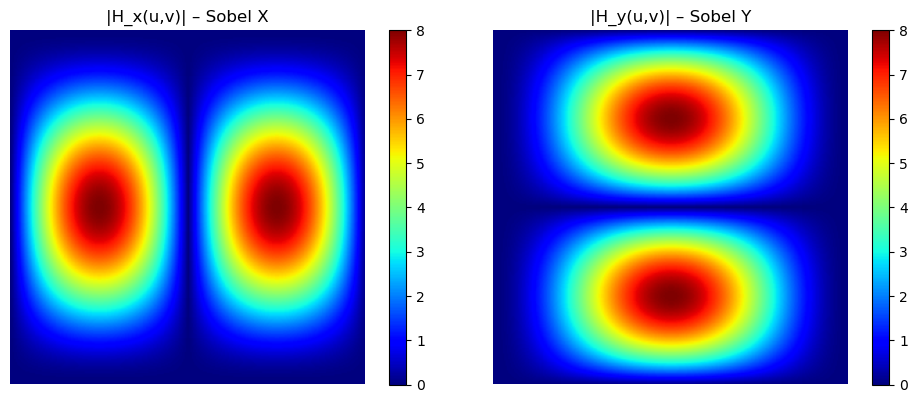

In [5]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1); plt.imshow(np.abs(fftshift(H_x)), cmap='jet'); plt.title('|H_x(u,v)| – Sobel X'); plt.colorbar(); plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(np.abs(fftshift(H_y)), cmap='jet'); plt.title('|H_y(u,v)| – Sobel Y'); plt.colorbar(); plt.axis('off')
plt.tight_layout()
plt.savefig('images/sobel_filter_responses.png', dpi=120)
plt.show()

**Observation:** both responses are zero at the centre (DC) → Sobel is a high-pass/derivative filter.
$H_x$ passes frequencies that vary along **x** (detects vertical edges), and $H_y$ passes frequencies varying along **y** (detects horizontal edges).

### Spectra and spatial results

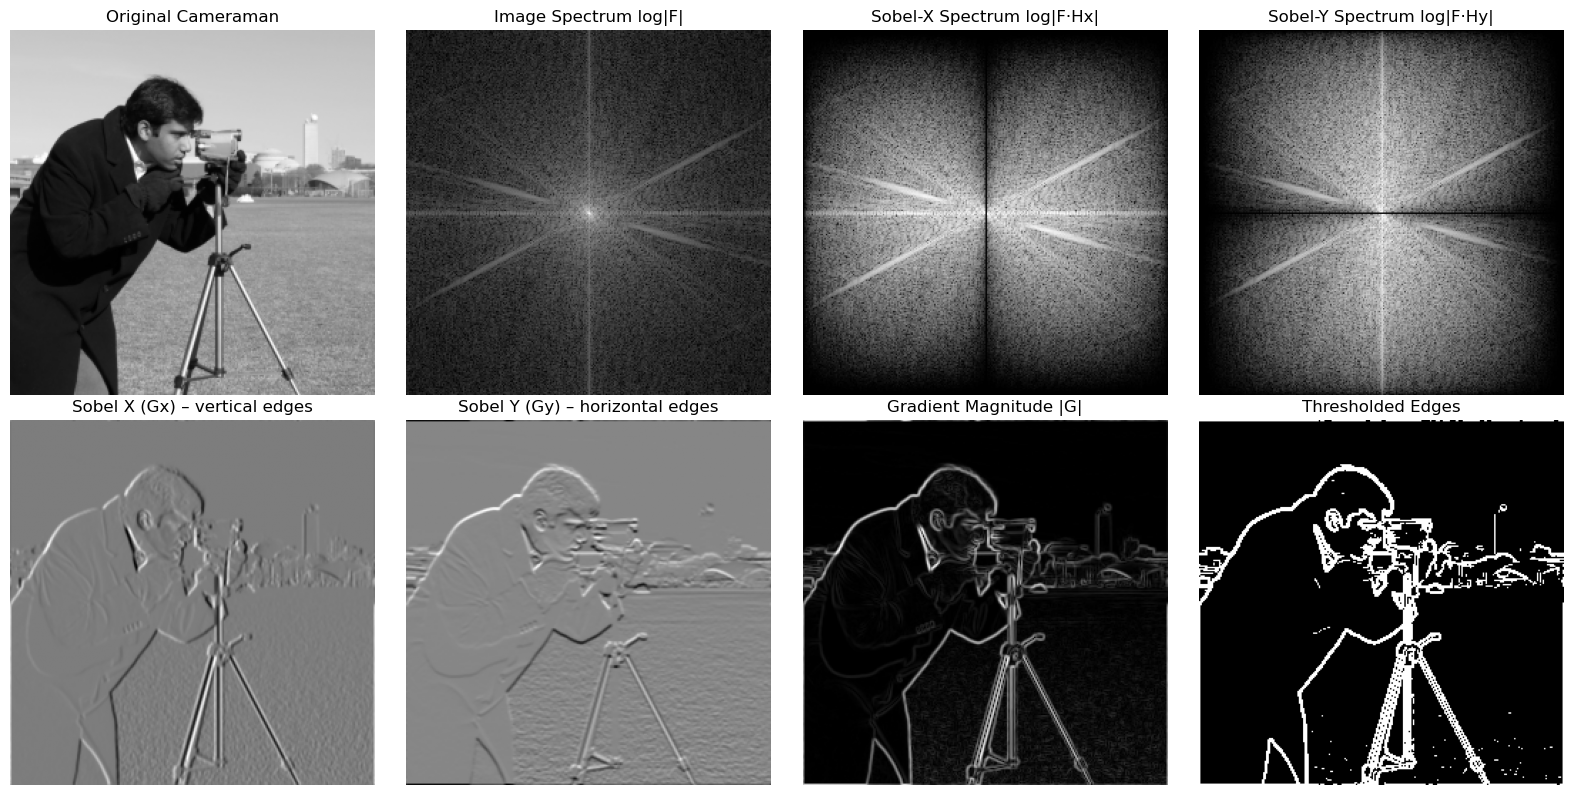

In [6]:
plt.figure(figsize=(16, 8))

plt.subplot(2, 4, 1); plt.imshow(image, cmap='gray'); plt.title('Original Cameraman'); plt.axis('off')
plt.subplot(2, 4, 2); plt.imshow(np.log(1 + np.abs(fftshift(F))), cmap='gray'); plt.title('Image Spectrum log|F|'); plt.axis('off')
plt.subplot(2, 4, 3); plt.imshow(np.log(1 + np.abs(fftshift(G_x_freq))), cmap='gray'); plt.title('Sobel-X Spectrum log|F·Hx|'); plt.axis('off')
plt.subplot(2, 4, 4); plt.imshow(np.log(1 + np.abs(fftshift(G_y_freq))), cmap='gray'); plt.title('Sobel-Y Spectrum log|F·Hy|'); plt.axis('off')

plt.subplot(2, 4, 5); plt.imshow(G_x, cmap='gray'); plt.title('Sobel X (Gx) – vertical edges'); plt.axis('off')
plt.subplot(2, 4, 6); plt.imshow(G_y, cmap='gray'); plt.title('Sobel Y (Gy) – horizontal edges'); plt.axis('off')
plt.subplot(2, 4, 7); plt.imshow(G_mag, cmap='gray'); plt.title('Gradient Magnitude |G|'); plt.axis('off')
plt.subplot(2, 4, 8); plt.imshow(G_mag > 0.5 * G_mag.mean() + G_mag.std(), cmap='gray'); plt.title('Thresholded Edges'); plt.axis('off')

plt.tight_layout()
plt.savefig('images/task_sobel_frequency.png', dpi=120)
plt.show()

io.imsave('images/sobel_magnitude.png', img_as_ubyte(G_mag / G_mag.max()))

### Verification against spatial-domain convolution
Multiplying FFTs is equivalent to **circular** convolution, so we compare with `scipy.signal.convolve2d(..., boundary='wrap')`. The difference should be ~0.

Max |Gx_freq - Gx_spatial| = 1.7763568394002505e-15
Max |Gy_freq - Gy_spatial| = 2.8622937353617317e-15


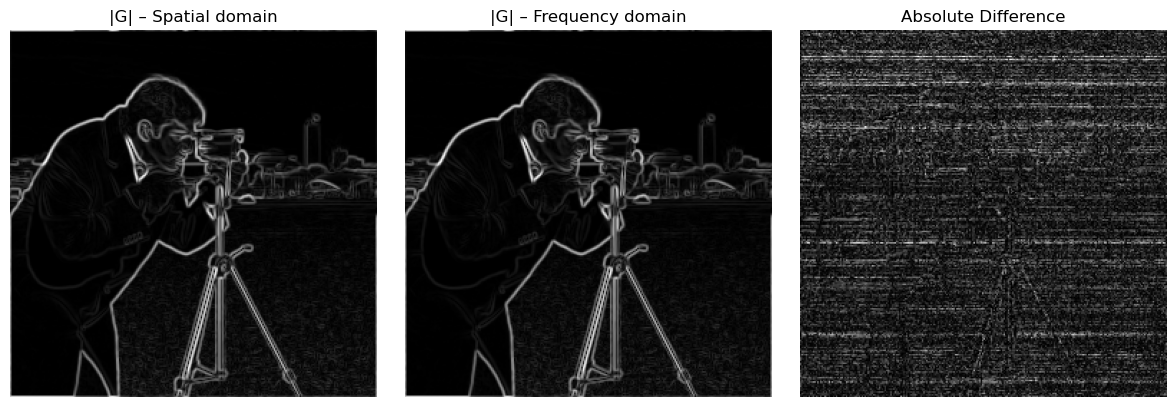

In [7]:
from scipy.signal import convolve2d

Gx_spatial = convolve2d(image, sobel_x, mode='same', boundary='wrap')
Gy_spatial = convolve2d(image, sobel_y, mode='same', boundary='wrap')

print('Max |Gx_freq - Gx_spatial| =', np.abs(G_x - Gx_spatial).max())
print('Max |Gy_freq - Gy_spatial| =', np.abs(G_y - Gy_spatial).max())

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1); plt.imshow(np.sqrt(Gx_spatial**2 + Gy_spatial**2), cmap='gray'); plt.title('|G| – Spatial domain'); plt.axis('off')
plt.subplot(1, 3, 2); plt.imshow(G_mag, cmap='gray'); plt.title('|G| – Frequency domain'); plt.axis('off')
plt.subplot(1, 3, 3); plt.imshow(np.abs(G_mag - np.sqrt(Gx_spatial**2 + Gy_spatial**2)), cmap='gray'); plt.title('Absolute Difference'); plt.axis('off')
plt.tight_layout()
plt.show()

## Conclusion
- The Sobel kernels were zero-padded to the image size, centred, and shifted with `ifftshift` so that their origin lies at (0,0); their FFT gives the filter transfer functions $H_x$, $H_y$.
- Multiplying the image spectrum by $H_x$ / $H_y$ and applying the inverse FFT produced the horizontal and vertical gradients — $G_x$ highlights **vertical edges** (e.g. the tripod legs and the man's coat), $G_y$ highlights **horizontal edges** (e.g. the horizon and the camera top).
- Both filters suppress the DC/low frequencies (high-pass), which is why flat regions (sky, grass) become dark in the magnitude image.
- The result matches spatial-domain circular convolution to machine precision, confirming the **Convolution Theorem**.
- Note: since FFT multiplication performs true convolution (kernel flipped), the sign of $G_x$/$G_y$ is inverted compared with correlation-based `cv2.filter2D`; the gradient magnitude is identical.